# Results

Clean accuracy (CA), attack success rate (ASR) and stealth (SSIM, PSNR, L2, L∞, LPIPS) for every attack
and poisoning rate. Figures are saved to `results/figures/`.

**Where the numbers come from.** `results/summary.csv` is a log that every evaluation appends to, so it
has repeated runs, and its older rows log both SIG modes as plain `sig`. The plots therefore use
`results/report_results.csv`, a cleaned-up table with one row per attack and poisoning rate that
matches Tables 3 and 5 of the report. Section 0 checks it against the latest rows of `summary.csv`.

0. Check against `summary.csv`
1. ASR vs poisoning rate
2. Clean accuracy
3. Stealth vs effectiveness
4. Fixed vs Adaptive SIG+WaNet (v1 and v2)
5. Adaptive ablation
6. What the models predict on triggered test images (Fixed vs Adaptive v2)
7. Which part of the trigger each model reacts to
8. Robustness: random seeds, validation-based selection, data augmentation, and why WaNet gains from augmentation
9. A second architecture (VGG-16)
10. How much the core results change with the random seed
11. A second dataset (GTSRB)

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = "results/figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 11, "axes.titlesize": 11, "axes.labelsize": 11,
                     "legend.fontsize": 9.5, "xtick.labelsize": 10, "ytick.labelsize": 10})

df = pd.read_csv("results/report_results.csv")
RATES = [0.005, 0.01, 0.05]
RATE_LABELS = ["0.5%", "1%", "5%"]
COLORS = {
    "Blend": "#1f77b4", "SIG (clean-label)": "#aec7e8", "SIG (dirty-label)": "#ff7f0e", "WaNet": "#2ca02c",
    "Blend+SIG": "#9467bd", "Blend+WaNet": "#8c564b", "SIG+WaNet (Fixed)": "#17becf", "Blend+SIG+WaNet": "#7f7f7f",
    "SIG+WaNet (Fixed, matched)": "#6a3d9a", "Adaptive v1": "#d62728", "Adaptive v2": "#2e7d32",
    "Adaptive spatial-only (v1 settings)": "#e377c2", "Adaptive freq-only (v1 settings)": "#bcbd22",
}
# marker shapes, line styles and bar hatching, so the figures still read when printed in greyscale
MARKERS = {
    "Blend": "o", "SIG (clean-label)": "v", "SIG (dirty-label)": "^", "WaNet": "s",
    "Blend+SIG": "D", "Blend+WaNet": "P", "SIG+WaNet (Fixed)": "o", "Blend+SIG+WaNet": "X",
    "SIG+WaNet (Fixed, matched)": "s", "Adaptive v1": "^", "Adaptive v2": "D",
    "Adaptive spatial-only (v1 settings)": "v", "Adaptive freq-only (v1 settings)": "P",
}
LINESTYLES = ["-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1))]
HATCHES = {"SIG+WaNet (Fixed)": "", "SIG+WaNet (Fixed, matched)": "///", "Adaptive v1": "...", "Adaptive v2": "xxx"}
df.pivot_table(index="attack", columns="poison_rate", values="asr", sort=False)

poison_rate,0.005,0.010,0.050
attack,,,
Blend,85.48,96.50,99.83
SIG (clean-label),27.80,65.33,89.90
SIG (dirty-label),97.56,98.97,99.96
WaNet,29.73,53.92,94.73
Blend+SIG,85.86,95.36,99.43
Blend+WaNet,63.19,83.72,98.34
SIG+WaNet (Fixed),87.36,95.28,99.01
"SIG+WaNet (Fixed, matched)",87.57,96.26,99.16
Blend+SIG+WaNet,78.33,89.62,97.79


## 0. Check against `summary.csv`

For every attack whose name in `summary.csv` is unambiguous, I take the most recent row per attack and
poisoning rate and compare it with the cleaned-up table. If they agree, the table really comes from the
evaluation runs.

In [2]:
# summary.csv started with 6 columns; later rows have 9 (L2, Linf and LPIPS were added later)
raw = pd.read_csv("results/summary.csv", skiprows=1, header=None,
                  names=["attack", "poison_rate", "clean_acc", "asr", "ssim", "psnr", "l2", "linf", "lpips"])
name_map = {"blend": "Blend", "sig_wanet": "SIG+WaNet (Fixed)", "sig_wanet_matched": "SIG+WaNet (Fixed, matched)", "blend_wanet": "Blend+WaNet", "blend_sig_wanet": "Blend+SIG+WaNet",
            "adaptive_hybrid": "Adaptive v2", "adaptive_spatial": "Adaptive spatial-only (v1 settings)",
            "adaptive_freq": "Adaptive freq-only (v1 settings)"}
latest = (raw[raw.attack.isin(name_map)].groupby(["attack", "poison_rate"]).tail(1)
          .assign(attack=lambda d: d.attack.map(name_map)))
cmp = latest.merge(df, on=["attack", "poison_rate"], suffixes=("_summary", "_report"))
cmp["asr_summary"] *= 100; cmp["clean_acc_summary"] *= 100
cmp["asr_diff"] = (cmp.asr_summary - cmp.asr_report).round(2)
cmp["ssim_diff"] = (cmp.ssim_summary - cmp.ssim_report).round(4)
cmp[["attack", "poison_rate", "asr_report", "asr_summary", "asr_diff", "ssim_report", "ssim_summary", "ssim_diff"]].round(4)

,attack,poison_rate,asr_report,asr_summary,asr_diff,ssim_report,ssim_summary,ssim_diff
0,Blend,0.005,85.48,85.4778,-0.0,0.8887,0.8887,0.0
1,Blend,0.010,96.50,96.5000,-0.0,0.8887,0.8887,0.0
2,Blend,0.050,99.83,99.8333,0.0,0.8887,0.8887,0.0
3,Blend+WaNet,0.005,63.19,63.1889,-0.0,0.9509,0.9509,-0.0
4,Blend+WaNet,0.010,83.72,83.7222,0.0,0.9509,0.9509,-0.0
5,Blend+WaNet,0.050,98.34,98.3444,0.0,0.9509,0.9509,-0.0
6,SIG+WaNet (Fixed),0.005,87.36,87.3556,-0.0,0.9429,0.9429,0.0
7,SIG+WaNet (Fixed),0.010,95.28,95.2778,-0.0,0.9429,0.9429,0.0
8,SIG+WaNet (Fixed),0.050,99.01,99.0111,0.0,0.9429,0.9429,0.0
9,Blend+SIG+WaNet,0.005,78.33,78.3333,0.0,0.9547,0.9547,0.0


If any difference above is not zero, a newer row for that configuration exists in `summary.csv`
(e.g. from a re-evaluation) and the table still holds the run used in the report.

## 1. ASR vs poisoning rate

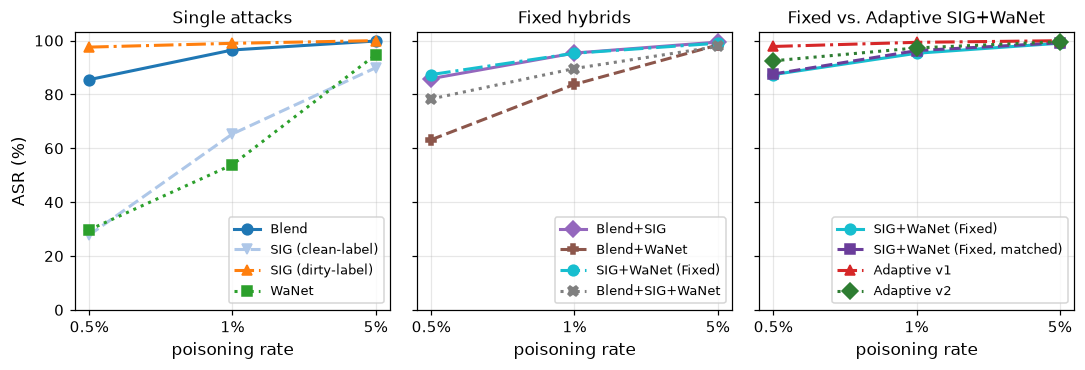

In [3]:
groups = {"Single attacks": ["Blend", "SIG (clean-label)", "SIG (dirty-label)", "WaNet"],
          "Fixed hybrids": ["Blend+SIG", "Blend+WaNet", "SIG+WaNet (Fixed)", "Blend+SIG+WaNet"],
          "Fixed vs. Adaptive SIG+WaNet": ["SIG+WaNet (Fixed)", "SIG+WaNet (Fixed, matched)", "Adaptive v1", "Adaptive v2"]}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharey=True)
for ax, (title, names) in zip(axes, groups.items()):
    for k, n in enumerate(names):
        sub = df[df.attack == n].sort_values("poison_rate")
        ax.plot(range(3), sub.asr, marker=MARKERS[n], ms=7, ls=LINESTYLES[k], color=COLORS[n], label=n, lw=2)
    ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate")
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8.5, loc="lower right")
axes[0].set_ylabel("ASR (%)"); axes[0].set_ylim(0, 103)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/asr_vs_poison_rate.png", bbox_inches="tight"); plt.show()

## 2. Clean accuracy

Every backdoored model stays within about 1 point of the clean model (the colour shows the difference),
so looking at the clean accuracy alone would not reveal the backdoors.

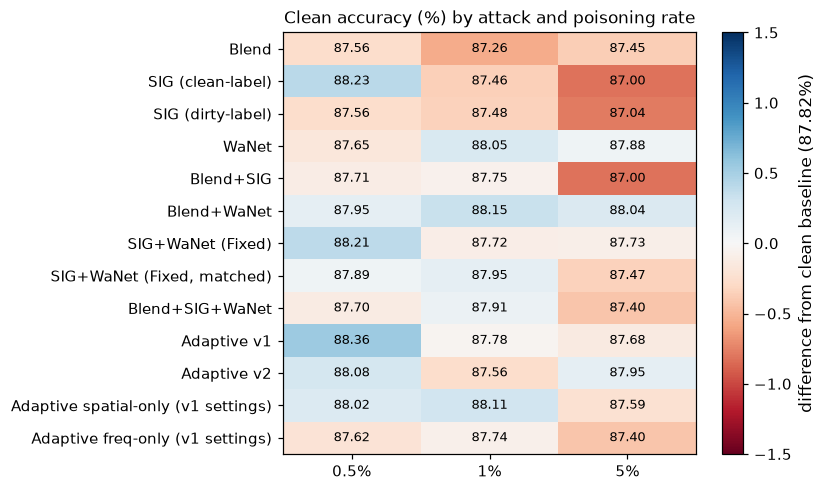

In [4]:
ca = df[df.group != "baseline"].pivot_table(index="attack", columns="poison_rate", values="clean_acc", sort=False)
baseline = df.loc[df.group == "baseline", "clean_acc"].item()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(ca.values - baseline, cmap="RdBu", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_yticks(range(len(ca))); ax.set_yticklabels(ca.index)
for i in range(ca.shape[0]):
    for j in range(ca.shape[1]):
        ax.text(j, i, f"{ca.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5)
plt.colorbar(im, label=f"difference from clean baseline ({baseline:.2f}%)")
ax.set_title("Clean accuracy (%) by attack and poisoning rate")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/clean_accuracy.png", bbox_inches="tight"); plt.show()

## 3. Stealth vs effectiveness

Each point is one attack at one poisoning rate. **Top right is better** (high ASR and high SSIM or
PSNR). The trade-off is clearest at 0.5%: the attacks are either effective (Blend, SIG) or stealthy
(WaNet, the three-way hybrid). Adaptive v2 moves the SIG+WaNet hybrid up and to the right of the Fixed
version.

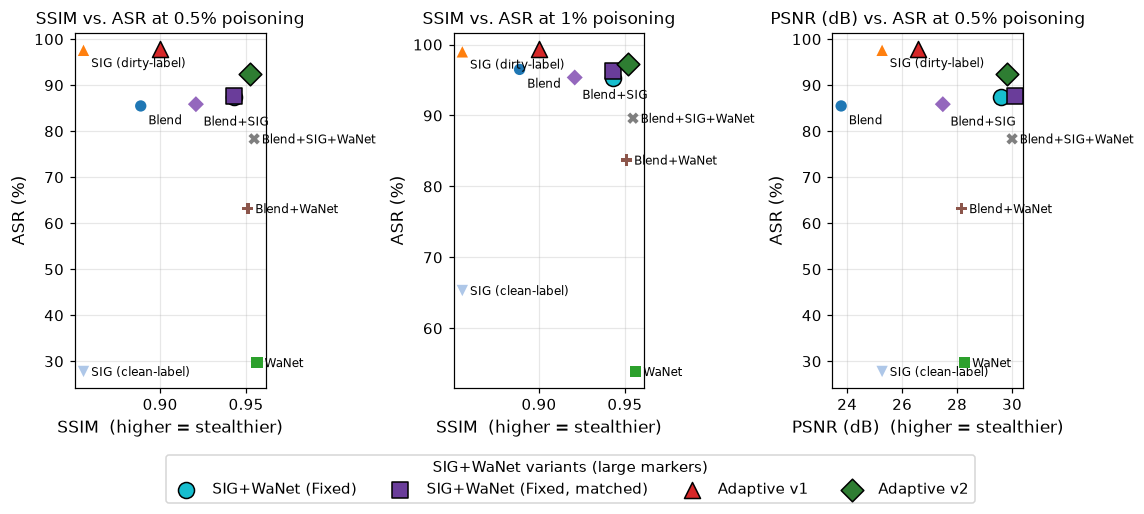

In [5]:
plot_names = [n for n in COLORS if "only" not in n]
# move some labels so they don't overlap
OFFSETS = {"SIG (dirty-label)": (5, -11), "Adaptive v1": (7, 3), "Adaptive v2": (7, 4),
           "SIG+WaNet (Fixed)": (7, -16), "Blend+SIG": (5, -14), "Blend": (5, -12), "SIG+WaNet (Fixed, matched)": (-58, -17)}
SHORT = {"SIG+WaNet (Fixed, matched)": "Fixed (matched)"}
fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.2))
for ax, (rate, metric, label) in zip(axes, [(0.005, "ssim", "SSIM"), (0.01, "ssim", "SSIM"), (0.005, "psnr", "PSNR (dB)")]):
    sub = df[(df.poison_rate == rate) & df.attack.isin(plot_names)]
    for _, r in sub.iterrows():
        big = r.attack.startswith("Adaptive") or "Fixed" in r.attack
        ax.scatter(r[metric], r.asr, s=110 if big else 55, color=COLORS[r.attack], marker=MARKERS[r.attack],
                   edgecolor="k" if big else "none", zorder=3, label=r.attack if big else None)
        if not big:   # the four SIG+WaNet variants are too close together for labels, so the legend names them
            ax.annotate(r.attack, (r[metric], r.asr), fontsize=8,
                        xytext=OFFSETS.get(r.attack, (5, -3)), textcoords="offset points")

    ax.set_xlabel(label + "  (higher = stealthier)"); ax.set_ylabel("ASR (%)")
    ax.set_title(f"{label} vs. ASR at {rate:.1%} poisoning".replace(".0%", "%")); ax.grid(alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9.5,
           title="SIG+WaNet variants (large markers)", title_fontsize=9.5, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/stealth_vs_asr.png", bbox_inches="tight"); plt.show()

## 4. Fixed vs Adaptive SIG+WaNet

Left: ASR at each poisoning rate. Right: each stealth metric relative to the Fixed hybrid (above 1 =
stealthier than Fixed; the distance metrics are flipped so that higher is always better).

**Fixed (matched)** is the same fixed hybrid but with v2's *average* strengths (warp 0.27, signal 10.6).
Comparing it with v2 separates what the adaptive strengths and mask do from what simply moving strength
from the warp to the signal does.

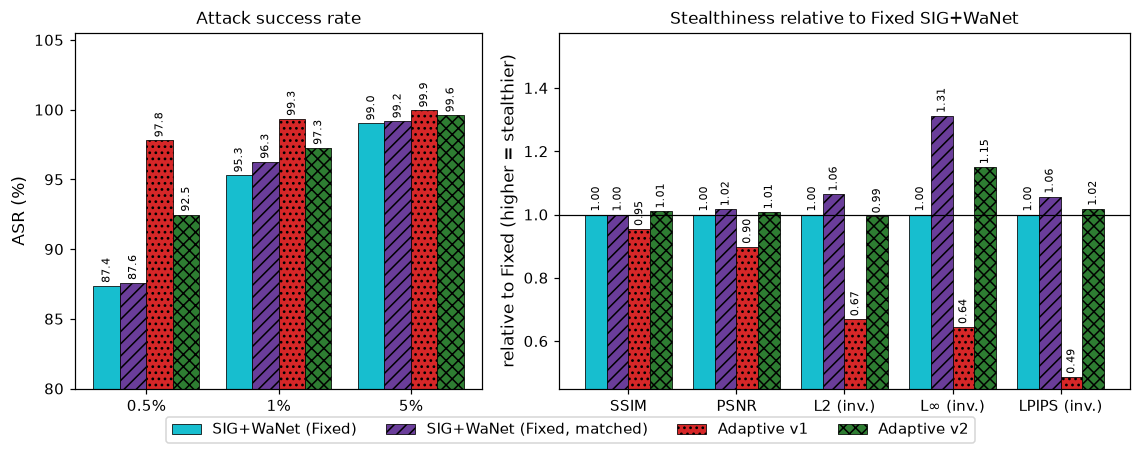

,clean_acc,ssim,psnr,l2,linf,lpips
attack,,,,,,
SIG+WaNet (Fixed),87.72,0.9429,29.60,1.8468,0.1461,0.0112
"SIG+WaNet (Fixed, matched)",87.95,0.9428,30.09,1.7369,0.1114,0.0106
Adaptive v1,87.78,0.8998,26.58,2.7608,0.2267,0.0230
Adaptive v2,87.56,0.9520,29.81,1.8581,0.1271,0.0110


In [6]:
names = ["SIG+WaNet (Fixed)", "SIG+WaNet (Fixed, matched)", "Adaptive v1", "Adaptive v2"]
sub = df[df.attack.isin(names)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1, 1.4]})
w = 0.2
offset = lambda k: (k - (len(names) - 1) / 2) * w
for k, n in enumerate(names):
    vals = sub[sub.attack == n].sort_values("poison_rate").asr.values
    bars = axes[0].bar(np.arange(3) + offset(k), vals, w, color=COLORS[n], label=n,
                       hatch=HATCHES[n], edgecolor="k", lw=0.5)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=7.5, rotation=90, padding=2)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(RATE_LABELS); axes[0].set_ylim(max(0, 5 * (sub.asr.min() // 5) - 5), 105.5)
axes[0].set_ylabel("ASR (%)"); axes[0].set_title("Attack success rate")

metrics = [("ssim", "SSIM", False), ("psnr", "PSNR", False), ("l2", "L2", True), ("linf", "L∞", True), ("lpips", "LPIPS", True)]
one = sub[sub.poison_rate == 0.01].set_index("attack")
ref = one.loc["SIG+WaNet (Fixed)"]
for k, n in enumerate(names):
    rel = [(ref[m] / one.loc[n, m]) if inv else (one.loc[n, m] / ref[m]) for m, _, inv in metrics]
    bars = axes[1].bar(np.arange(len(metrics)) + offset(k), rel, w, color=COLORS[n], label=n,
                       hatch=HATCHES[n], edgecolor="k", lw=0.5)
    axes[1].bar_label(bars, fmt="%.2f", fontsize=7.5, rotation=90, padding=2)
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_xticks(range(len(metrics))); axes[1].set_xticklabels([f"{l}" + (" (inv.)" if inv else "") for _, l, inv in metrics])
axes[1].set_ylabel("relative to Fixed (higher = stealthier)")
axes[1].set_ylim(0.45, 1.2 * max(p.get_height() for p in axes[1].patches))
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(names), fontsize=9.5, bbox_to_anchor=(0.5, -0.04))
axes[1].set_title("Stealthiness relative to Fixed SIG+WaNet")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fixed_vs_adaptive.png", bbox_inches="tight"); plt.show()

one[["clean_acc", "ssim", "psnr", "l2", "linf", "lpips"]].loc[names]

## 5. Adaptive ablation

The ablations use the v1 settings. The signal (SIG) part on its own gets almost the same ASR as the full
adaptive hybrid, while the warp (WaNet) part on its own is weak at low poisoning rates. This is why v2
moves strength from the warp to the signal.

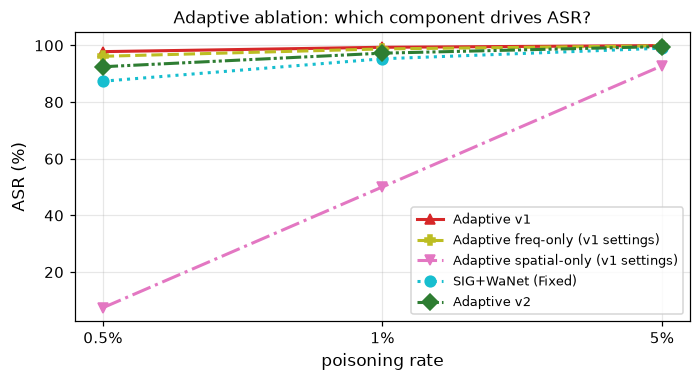

In [7]:
names = ["Adaptive v1", "Adaptive freq-only (v1 settings)", "Adaptive spatial-only (v1 settings)",
         "SIG+WaNet (Fixed)", "Adaptive v2"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, n in enumerate(names):
    s = df[df.attack == n].sort_values("poison_rate")
    ax.plot(range(3), s.asr, marker=MARKERS[n], ms=7, lw=2, color=COLORS[n], label=n, ls=LINESTYLES[k])
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate"); ax.set_ylabel("ASR (%)")
ax.set_title("Adaptive ablation: which component drives ASR?"); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/adaptive_ablation.png", bbox_inches="tight"); plt.show()

## 6. What the models predict on triggered test images

ASR is a percentage over 9,000 test images. This shows what that means for single images: the Fixed
SIG+WaNet and Adaptive v2 models trained at **0.5%** poisoning (where the gap is biggest, 87.36% vs
92.47%) classify the same triggered images. They are just the **first 8 non-airplane test images**, not
picked by hand. Green = the backdoor worked (predicted airplane), red = the model ignored the trigger.

SIG+WaNet (Fixed): 6/8 triggered images classified as airplane
Adaptive v2: 7/8 triggered images classified as airplane


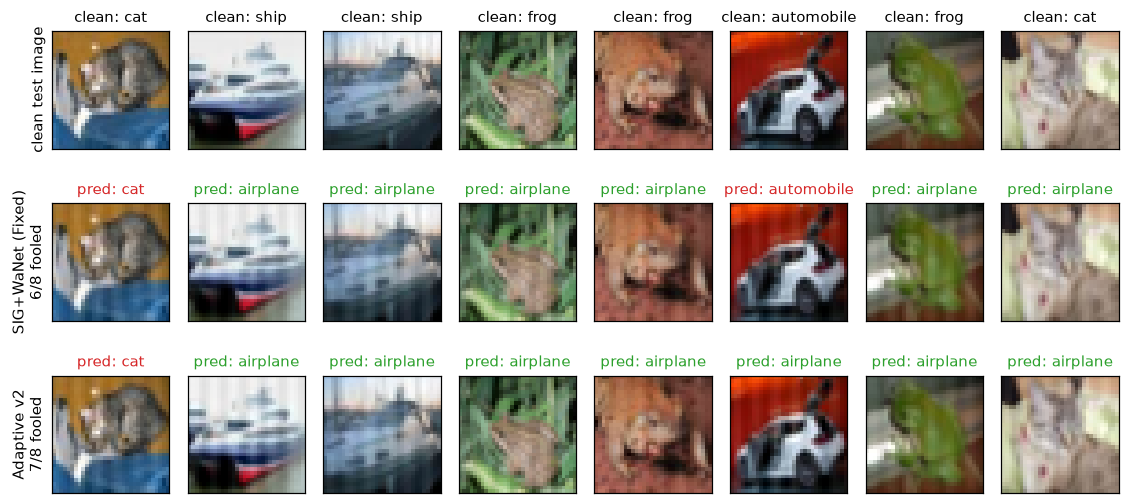

In [8]:
import sys, torch, torchvision
import torchvision.transforms as T
sys.path.insert(0, os.getcwd())
from config import cfg
from utils import set_seed, load_checkpoint
from models.resnet import get_model
from datasets.poison_dataset import TestPoisonedDataset

test_base = torchvision.datasets.CIFAR10(root=cfg.data_root, train=False, download=True)
CLASSES = test_base.classes
normalize = T.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
N_SHOW, RATE = 8, 0.005

def triggered_predictions(attack, rate, n):
    saved = (cfg.attack_name, cfg.poison_rate)
    cfg.attack_name, cfg.poison_rate = attack, rate
    try:
        set_seed(cfg.seed)
        test_set = TestPoisonedDataset(test_base, cfg)
        model = get_model(cfg.model_name, cfg.num_classes).to(cfg.device)
        load_checkpoint(model, None, f"{cfg.checkpoint_dir}/{cfg.tag()}_final.pt", cfg.device)
        model.eval()
        idx = test_set.eval_indices[:n]
        imgs = torch.stack([test_set[k][0] for k in range(n)])
        with torch.no_grad():
            preds = model(torch.stack([normalize(x) for x in imgs]).to(cfg.device)).argmax(1).cpu()
    finally:
        cfg.attack_name, cfg.poison_rate = saved
    return idx, imgs, preds

rows = {"SIG+WaNet (Fixed)": triggered_predictions("sig_wanet", RATE, N_SHOW),
        "Adaptive v2": triggered_predictions("adaptive_hybrid", RATE, N_SHOW)}
idx = rows["SIG+WaNet (Fixed)"][0]
assert idx == rows["Adaptive v2"][0]

fig, axes = plt.subplots(3, N_SHOW, figsize=(1.3 * N_SHOW, 5.0))
for c, i in enumerate(idx):
    img, label = test_base[i]
    axes[0, c].imshow(img); axes[0, c].set_title(f"clean: {CLASSES[label]}", fontsize=9.5)
for r, (name, (_, imgs, preds)) in enumerate(rows.items(), start=1):
    for c in range(N_SHOW):
        axes[r, c].imshow(imgs[c].permute(1, 2, 0).clamp(0, 1).numpy())
        fooled = preds[c].item() == cfg.target_label
        axes[r, c].set_title(f"pred: {CLASSES[preds[c]]}", fontsize=9.5, color="tab:green" if fooled else "tab:red")
    n_fooled = int((preds == cfg.target_label).sum())
    axes[r, 0].set_ylabel(f"{name}\n{n_fooled}/{N_SHOW} fooled", fontsize=9.5)
    print(f"{name}: {n_fooled}/{N_SHOW} triggered images classified as {CLASSES[cfg.target_label]}")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("clean test image", fontsize=9.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/trigger_predictions.png", bbox_inches="tight"); plt.show()

## 7. Which part of the trigger does each model react to?

From `evaluate_components.py` (no retraining): each trained SIG+WaNet model is tested with the full
trigger, with only the sine signal (SIG) and with only the warp, each at the strength it was trained
with.

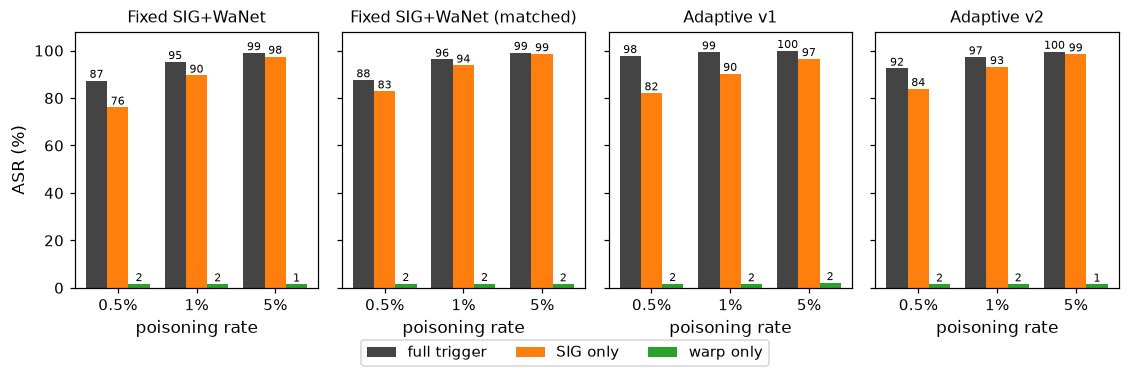

,model,poison_rate,asr_full,asr_sig_only,asr_warp_only
0,Fixed SIG+WaNet,0.005,87.36,76.04,1.68
1,Fixed SIG+WaNet,0.010,95.28,89.53,1.58
2,Fixed SIG+WaNet,0.050,99.01,97.50,1.48
3,Fixed SIG+WaNet (matched),0.005,87.57,82.87,1.71
4,Fixed SIG+WaNet (matched),0.010,96.26,93.78,1.74
5,Fixed SIG+WaNet (matched),0.050,99.16,98.58,1.59
6,Adaptive v1,0.005,97.80,82.09,1.72
7,Adaptive v1,0.010,99.34,90.28,1.61
8,Adaptive v1,0.050,99.94,96.51,2.10
9,Adaptive v2,0.005,92.47,83.89,1.50


In [9]:
comp = pd.read_csv("results/component_asr.csv")
models = list(dict.fromkeys(comp.model))
fig, axes = plt.subplots(1, len(models), figsize=(2.6 * len(models), 3.3), sharey=True)
for ax, m in zip(np.atleast_1d(axes), models):
    s = comp[comp.model == m].sort_values("poison_rate")
    for k, (col, lab, colr) in enumerate([("asr_full", "full trigger", "#444444"), ("asr_sig_only", "SIG only", "#ff7f0e"),
                                          ("asr_warp_only", "warp only", "#2ca02c")]):
        bars = ax.bar(np.arange(len(s)) + (k - 1) * 0.27, 100 * s[col], 0.27, label=lab, color=colr)
        ax.bar_label(bars, fmt="%.0f", fontsize=7.5)
    ax.set_xticks(range(len(s))); ax.set_xticklabels([f"{r:.1%}".replace(".0%", "%") for r in s.poison_rate])
    ax.set_title(m, fontsize=10.5); ax.set_xlabel("poisoning rate"); ax.set_ylim(0, 108)
np.atleast_1d(axes)[0].set_ylabel("ASR (%)")
fig.legend(*np.atleast_1d(axes)[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.05))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/component_asr.png", bbox_inches="tight"); plt.show()
comp.assign(**{c: (100 * comp[c]).round(2) for c in ["asr_full", "asr_sig_only", "asr_warp_only"]})

## 8. Robustness: random seeds, validation-based selection and data augmentation

**Seeds.** The Fixed hybrid, the matched baseline and Adaptive v2 were trained again with seeds 1 to 4
at 0.5% and 1%, so there are five runs of each. The seed changes which images get poisoned *and* the random parts of the trigger (the
WaNet field and the cover samples), so the spread shows how much a whole run varies. Seed 42 is the
original run in Table 5.

In [10]:
SEED_ATTACKS = {"sig_wanet": "SIG+WaNet (Fixed)", "sig_wanet_matched": "SIG+WaNet (Fixed, matched)",
                "adaptive_hybrid": "Adaptive v2"}
last = raw.groupby(["attack", "poison_rate"]).tail(1).set_index(["attack", "poison_rate"])
rows = []
for key, name in SEED_ATTACKS.items():
    for rate in (0.005, 0.01):
        for seed, suffix in ((42, ""), (1, "_s1"), (2, "_s2"), (3, "_s3"), (4, "_s4")):
            if (key + suffix, rate) in last.index:
                r = last.loc[(key + suffix, rate)]
                rows.append({"attack": name, "poison_rate": rate, "seed": seed,
                             "clean_acc": 100 * r.clean_acc, "asr": 100 * r.asr, "ssim": r.ssim, "psnr": r.psnr})
seeds = pd.DataFrame(rows)
seeds.to_csv("results/seed_results.csv", index=False)
seed_summary = (seeds.groupby(["attack", "poison_rate"], sort=False)
                .agg(n_seeds=("asr", "size"), asr_mean=("asr", "mean"), asr_std=("asr", "std"),
                     asr_min=("asr", "min"), asr_max=("asr", "max"), ca_mean=("clean_acc", "mean"),
                     ca_std=("clean_acc", "std")).reset_index())
seed_summary.round(2)

,attack,poison_rate,n_seeds,asr_mean,asr_std,asr_min,asr_max,ca_mean,ca_std
0,SIG+WaNet (Fixed),0.00,5,88.30,1.98,86.14,91.42,88.06,0.21
1,SIG+WaNet (Fixed),0.01,5,95.34,0.49,94.88,96.11,87.86,0.21
2,"SIG+WaNet (Fixed, matched)",0.00,5,88.48,1.36,87.47,90.53,88.24,0.21
3,"SIG+WaNet (Fixed, matched)",0.01,5,95.51,1.12,94.31,97.06,87.90,0.13
4,Adaptive v2,0.00,5,92.26,0.89,90.76,92.91,88.12,0.32
5,Adaptive v2,0.01,5,97.29,0.56,96.68,98.16,87.98,0.31


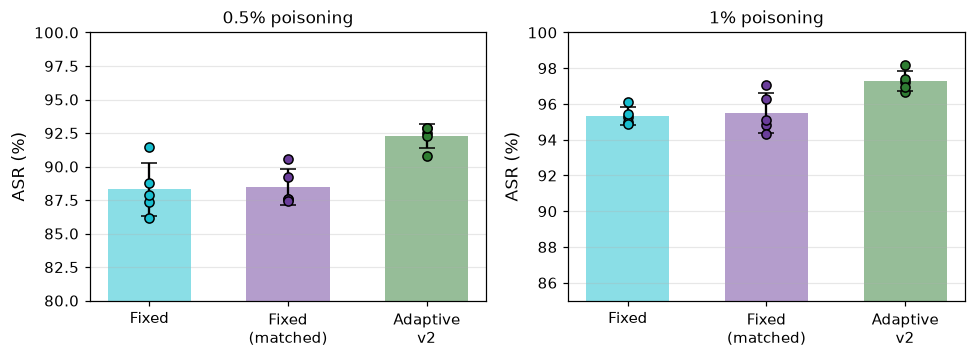

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, rate in zip(axes, (0.005, 0.01)):
    for k, name in enumerate(SEED_ATTACKS.values()):
        d = seeds[(seeds.attack == name) & (seeds.poison_rate == rate)]
        ax.bar(k, d.asr.mean(), 0.6, color=COLORS[name], alpha=0.5)
        ax.errorbar(k, d.asr.mean(), yerr=d.asr.std(), color="k", capsize=5)
        ax.scatter(np.full(len(d), k), d.asr, color=COLORS[name], edgecolor="k", zorder=3)
    ax.set_xticks(range(len(SEED_ATTACKS)))
    ax.set_xticklabels(["Fixed", "Fixed\n(matched)", "Adaptive\nv2"])
    lo = seeds[seeds.poison_rate == rate].asr.min()
    ax.set_ylim(5 * (lo // 5) - 5, 100); ax.grid(alpha=0.3, axis="y")
    ax.set_title(f"{rate:.1%} poisoning".replace(".0%", "%")); ax.set_ylabel("ASR (%)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/seed_variation.png", bbox_inches="tight"); plt.show()

**Is v2's lead over the Fixed hybrid more than run-to-run noise?** For each seed the difference
v2 - Fixed (and v2 - matched) is computed on the same seed, and a paired t-test checks whether the mean
difference over the five seeds is different from zero. The 95% confidence interval is for the mean
difference.

In [12]:
from scipy import stats
rows = []
for rate in (0.005, 0.01):
    piv = seeds[seeds.poison_rate == rate].pivot(index="seed", columns="attack", values="asr")
    for other in ("SIG+WaNet (Fixed)", "SIG+WaNet (Fixed, matched)"):
        diff = piv["Adaptive v2"] - piv[other]
        n = len(diff)
        half = stats.t.ppf(0.975, n - 1) * diff.std(ddof=1) / np.sqrt(n)
        rows.append({"poison_rate": rate, "comparison": f"v2 - {other}", "n_seeds": n,
                     "mean_diff": diff.mean(), "sd_diff": diff.std(ddof=1), "min_diff": diff.min(), "max_diff": diff.max(),
                     "ci95_low": diff.mean() - half, "ci95_high": diff.mean() + half,
                     "t": stats.ttest_rel(piv["Adaptive v2"], piv[other]).statistic,
                     "p_value": stats.ttest_rel(piv["Adaptive v2"], piv[other]).pvalue,
                     "seeds_v2_ahead": int((diff > 0).sum())})
paired = pd.DataFrame(rows)
paired.to_csv("results/seed_paired_tests.csv", index=False)
paired.round(4)

,poison_rate,comparison,n_seeds,mean_diff,sd_diff,min_diff,max_diff,ci95_low,ci95_high,t,p_value,seeds_v2_ahead
0,0.005,v2 - SIG+WaNet (Fixed),5,3.9533,2.2439,0.8333,6.7667,1.1672,6.7395,3.9396,0.0170,5
1,0.005,"v2 - SIG+WaNet (Fixed, matched)",5,3.7800,1.3203,2.3667,5.4444,2.1406,5.4194,6.4019,0.0031,5
2,0.010,v2 - SIG+WaNet (Fixed),5,1.9511,0.1559,1.6889,2.0889,1.7576,2.1447,27.9896,0.0000,5
3,0.010,"v2 - SIG+WaNet (Fixed, matched)",5,1.7800,0.7284,1.0000,2.6556,0.8756,2.6844,5.4642,0.0055,5


**Choosing the v2 settings on a validation split.** I first picked the v2 settings using the test-set
ASR at 0.5%, which is biased. To fix that, the Fixed hybrid and three candidate settings were trained
again at 0.5% on 45,000 training images (`--holdout 5000`) and compared only on the 5,000 held-out
training images (`select_adaptive_params.py`). The rule was fixed beforehand: out of the candidates
that beat the Fixed hybrid on validation ASR, take the one with the best SSIM, as long as its PSNR is
not worse.

In [13]:
val = pd.read_csv("results/validation_selection.csv")
val.assign(val_ca=100 * val.val_ca, val_asr=100 * val.val_asr).round(4)

,candidate,checkpoint,val_ca,val_asr,val_ssim,val_psnr,selected
0,Fixed SIG+WaNet,cifar10_resnet18_sig_wanet_val5000_pr0.005_fin...,87.32,88.7140,0.9430,29.6208,False
1,Candidate A (first attempt),cifar10_resnet18_adaptive_hybrid_val5000_candA...,86.14,81.0421,0.9654,30.4239,False
2,Candidate C1 (current v2),cifar10_resnet18_adaptive_hybrid_val5000_candC...,87.16,90.8647,0.9518,29.8464,True
3,Candidate C2,cifar10_resnet18_adaptive_hybrid_val5000_candC...,87.12,92.7051,0.9508,29.4416,False


**Data augmentation.** The clean model, WaNet, the Fixed hybrid and Adaptive v2 were trained again at
1% with random cropping (4-pixel padding) and horizontal flipping, applied after poisoning so the
poisoned images get augmented too. The trigger is tested without augmentation.

In [14]:
AUG = {"clean": ("Clean", 0.0), "wanet": ("WaNet", 0.01),
       "sig_wanet": ("SIG+WaNet (Fixed)", 0.01), "adaptive_hybrid": ("Adaptive v2", 0.01)}
rows = []
for key, (name, rate) in AUG.items():
    base = df[(df.attack == name) & (df.poison_rate == rate)]
    r = last.loc[(key + "_aug", rate)] if (key + "_aug", rate) in last.index else None
    rows.append({"attack": name, "poison_rate": rate,
                 "ca_no_aug": base.clean_acc.iloc[0] if len(base) else np.nan,
                 "ca_aug": 100 * r.clean_acc if r is not None else np.nan,
                 "asr_no_aug": base.asr.iloc[0] if len(base) and name != "Clean" else np.nan,
                 "asr_aug": 100 * r.asr if r is not None and name != "Clean" else np.nan})
aug = pd.DataFrame(rows)
aug.to_csv("results/augment_results.csv", index=False)
aug.round(2)

,attack,poison_rate,ca_no_aug,ca_aug,asr_no_aug,asr_aug
0,Clean,0.00,87.82,94.57,NaN,NaN
1,WaNet,0.01,88.05,94.74,53.92,69.73
2,SIG+WaNet (Fixed),0.01,87.72,94.46,95.28,96.36
3,Adaptive v2,0.01,87.56,94.55,97.26,97.39


### 8b. Why does WaNet's ASR go up with augmentation?

WaNet's ASR at 1% went from 53.9% without augmentation to 69.7% with crop + flip. Three checks:

1. **Is it just noise?** Repeat both settings with a second seed.
2. **Which augmentation does it?** Train with only cropping and with only flipping.
3. **Memorising vs learning the warp.** Compare the model's ASR on its own poisoned *training* images
   (the ones that aren't airplanes, exactly as trained) with its ASR on poisoned *test* images. A model
   that has memorised the individual poisoned images does much better on the first. Also check whether
   Activation Clustering still separates the poisoned training images (it did for the WaNet model
   without augmentation, section 3 of the defence notebook).

In [15]:
WANET_RUNS = [("No augmentation", "wanet", 42), ("No augmentation", "wanet_s1", 1),
              ("Crop + flip", "wanet_aug", 42), ("Crop + flip", "wanet_s1_aug", 1),
              ("Crop only", "wanet_augcrop", 42), ("Flip only", "wanet_augflip", 42)]
wanet_rows = []
for setting, key, seed in WANET_RUNS:
    r = last.loc[(key, 0.01)]
    wanet_rows.append({"setting": setting, "seed": seed, "key": key, "clean_acc": 100 * r.clean_acc, "asr": 100 * r.asr})
wanet_df = pd.DataFrame(wanet_rows)
wanet_df.round(2)

,setting,seed,key,clean_acc,asr
0,No augmentation,42,wanet,88.05,53.92
1,No augmentation,1,wanet_s1,88.06,50.24
2,Crop + flip,42,wanet_aug,94.74,69.73
3,Crop + flip,1,wanet_s1_aug,94.65,56.50
4,Crop only,42,wanet_augcrop,93.17,69.14
5,Flip only,42,wanet_augflip,91.19,70.88


In [16]:
from datasets.poison_dataset import PoisonedDataset, build_attack
from defenses.spectral import extract_features, activation_clustering, spectral_signatures
train_base = torchvision.datasets.CIFAR10(root=cfg.data_root, train=True, download=True)
train_labels = np.array(train_base.targets)

def wanet_model(key, seed):
    tag_rest = key[len("wanet"):]
    cfg.attack_name, cfg.poison_rate, cfg.seed = "wanet", 0.01, seed
    set_seed(seed)
    ds = PoisonedDataset(train_base, cfg, train=True)         # the same poisoned training set as in training
    set_seed(seed)
    attack = build_attack(cfg)                                 # and the same trigger as evaluate.py
    m = get_model("resnet18", cfg.num_classes).to(cfg.device)
    load_checkpoint(m, None, f"checkpoints/cifar10_resnet18_wanet{tag_rest}_pr0.01_final.pt", cfg.device)
    cfg.seed = cfg.DEFAULT_SEED
    return ds, attack, m.eval()

@torch.no_grad()
def target_rate(m, imgs):
    return float(torch.cat([m(normalize(imgs[i:i + 500]).to(cfg.device)).argmax(1).cpu()
                            for i in range(0, len(imgs), 500)]).eq(cfg.target_label).float().mean())

test_x = torch.stack([T.ToTensor()(test_base[i][0]) for i in range(len(test_base))])
test_nt = test_x[np.array(test_base.targets) != cfg.target_label]
mem_rows = []
for setting, key, seed in WANET_RUNS:
    ds, attack, m = wanet_model(key, seed)
    pidx = sorted(i for i in ds.poison_indices if train_labels[i] != cfg.target_label)
    train_p = torch.stack([ds[i][0] for i in pidx])            # poisoned training images exactly as the model saw them
    test_p = torch.stack([attack.poison(x) for x in test_nt])
    idx = sorted(set(np.where(train_labels == cfg.target_label)[0]) | set(ds.poison_indices))
    items = [ds[i] for i in idx]
    feats = extract_features(m, torch.stack([x for x, _, _ in items]), normalize, device=cfg.device)
    is_p = np.array([bool(p) for _, _, p in items])
    ac, sp = activation_clustering(feats, is_p), spectral_signatures(feats, is_p)
    mem_rows.append({"setting": setting, "seed": seed, "asr_train_poison": 100 * target_rate(m, train_p),
                     "asr_test": 100 * target_rate(m, test_p), "ac_precision": 100 * ac["ac_precision"],
                     "ac_recall": 100 * ac["ac_recall"], "ss_recall": 100 * sp["ss_recall"]})
    print(mem_rows[-1], flush=True)
mem_df = pd.DataFrame(mem_rows)
mem_df["memorisation_gap"] = mem_df.asr_train_poison - mem_df.asr_test
mem_df.to_csv("results/wanet_augmentation_analysis.csv", index=False)
mem_df.round(2)

{'setting': 'No augmentation', 'seed': 42, 'asr_train_poison': 100.0, 'asr_test': 53.922224044799805, 'ac_precision': 98.9795918367347, 'ac_recall': 77.60000000000001, 'ss_recall': 89.60000000000001}


{'setting': 'No augmentation', 'seed': 1, 'asr_train_poison': 100.0, 'asr_test': 50.244444608688354, 'ac_precision': 99.17355371900827, 'ac_recall': 72.0, 'ss_recall': 85.39999999999999}


{'setting': 'Crop + flip', 'seed': 42, 'asr_train_poison': 100.0, 'asr_test': 69.74444389343262, 'ac_precision': 99.77116704805492, 'ac_recall': 87.2, 'ss_recall': 91.0}


{'setting': 'Crop + flip', 'seed': 1, 'asr_train_poison': 99.54954981803894, 'asr_test': 56.48888945579529, 'ac_precision': 99.74554707379136, 'ac_recall': 78.4, 'ss_recall': 83.2}


{'setting': 'Crop only', 'seed': 42, 'asr_train_poison': 100.0, 'asr_test': 69.12222504615784, 'ac_precision': 99.27360774818402, 'ac_recall': 82.0, 'ss_recall': 89.60000000000001}


{'setting': 'Flip only', 'seed': 42, 'asr_train_poison': 100.0, 'asr_test': 70.87777853012085, 'ac_precision': 100.0, 'ac_recall': 84.2, 'ss_recall': 91.2}


,setting,seed,asr_train_poison,asr_test,ac_precision,ac_recall,ss_recall,memorisation_gap
0,No augmentation,42,100.00,53.92,98.98,77.6,89.6,46.08
1,No augmentation,1,100.00,50.24,99.17,72.0,85.4,49.76
2,Crop + flip,42,100.00,69.74,99.77,87.2,91.0,30.26
3,Crop + flip,1,99.55,56.49,99.75,78.4,83.2,43.06
4,Crop only,42,100.00,69.12,99.27,82.0,89.6,30.88
5,Flip only,42,100.00,70.88,100.00,84.2,91.2,29.12


## 9. A second architecture: VGG-16

The clean model and the Fixed vs Adaptive v2 comparison were trained again with a CIFAR-style VGG-16
(with batch norm) and everything else unchanged, to check that the result isn't specific to ResNet-18.
The trigger is built before the model, so it is the same on both architectures and the stealth numbers
don't change.

In [17]:
ARCH = {"Clean": ("clean", "vgg16_clean"), "SIG+WaNet (Fixed)": ("sig_wanet", "vgg16_sig_wanet"),
        "Adaptive v2": ("adaptive_hybrid", "vgg16_adaptive_hybrid")}
rows = []
for name, (rn, vg) in ARCH.items():
    for rate in ((0.0,) if name == "Clean" else (0.005, 0.01, 0.05)):
        res = df[(df.attack == name) & (df.poison_rate == rate)].iloc[0]
        v = last.loc[(vg, rate)]
        rows.append({"attack": name, "poison_rate": rate, "resnet_ca": res.clean_acc, "vgg_ca": 100 * v.clean_acc,
                     "resnet_asr": res.asr, "vgg_asr": 100 * v.asr if name != "Clean" else np.nan})
arch = pd.DataFrame(rows)
arch.to_csv("results/architecture_results.csv", index=False)
arch.round(2)

,attack,poison_rate,resnet_ca,vgg_ca,resnet_asr,vgg_asr
0,Clean,0.00,87.82,89.64,NaN,NaN
1,SIG+WaNet (Fixed),0.00,88.21,89.13,87.36,86.63
2,SIG+WaNet (Fixed),0.01,87.72,89.33,95.28,92.78
3,SIG+WaNet (Fixed),0.05,87.73,88.38,99.01,98.58
4,Adaptive v2,0.00,88.08,89.09,92.47,90.97
5,Adaptive v2,0.01,87.56,89.16,97.26,95.10
6,Adaptive v2,0.05,87.95,88.74,99.59,99.40


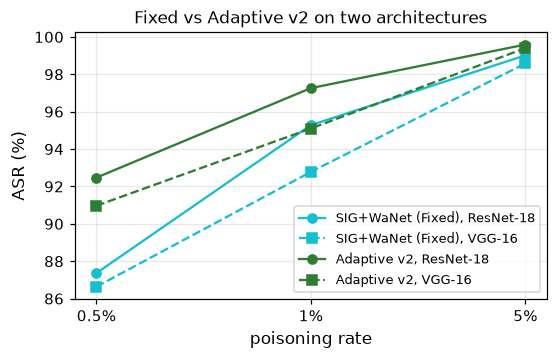

In [18]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
for name in ["SIG+WaNet (Fixed)", "Adaptive v2"]:
    d = arch[arch.attack == name]
    ax.plot(range(3), d.resnet_asr, "o-", color=COLORS[name], label=f"{name}, ResNet-18")
    ax.plot(range(3), d.vgg_asr, "s--", color=COLORS[name], label=f"{name}, VGG-16")
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate")
ax.set_ylabel("ASR (%)"); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
ax.set_title("Fixed vs Adaptive v2 on two architectures")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/architecture_comparison.png", bbox_inches="tight"); plt.show()

## 10. How much do the core results change with the random seed?

Table 3 is a single run per attack (seed 42). To see whether its ranking holds, every core attack was
trained once more at 1% poisoning with seed 1 (WaNet and SIG+WaNet already had a seed-1 run from
section 8), plus the clean model.

In [19]:
CORE = {"Clean": ("clean_s1", 0.0), "Blend": ("blend_s1", 0.01), "SIG (clean-label)": ("sig_clean_s1", 0.01),
        "SIG (dirty-label)": ("sig_dirty_s1", 0.01), "WaNet": ("wanet_s1", 0.01), "Blend+SIG": ("blend_sig_s1", 0.01),
        "Blend+WaNet": ("blend_wanet_s1", 0.01), "SIG+WaNet (Fixed)": ("sig_wanet_s1", 0.01),
        "Blend+SIG+WaNet": ("blend_sig_wanet_s1", 0.01)}
rows = []
for name, (key, rate) in CORE.items():
    base = df[(df.attack == name) & (df.poison_rate == rate)].iloc[0]
    r = last.loc[(key, rate)]
    rows.append({"attack": name, "poison_rate": rate, "ca_seed42": base.clean_acc, "ca_seed1": 100 * r.clean_acc,
                 "asr_seed42": base.asr if name != "Clean" else np.nan,
                 "asr_seed1": 100 * r.asr if name != "Clean" else np.nan})
core = pd.DataFrame(rows)
core["asr_diff"] = core.asr_seed1 - core.asr_seed42
core.to_csv("results/core_seed_results.csv", index=False)
att = core.dropna(subset=["asr_seed42"])
rho = stats.spearmanr(att.asr_seed42, att.asr_seed1).statistic
print("ASR ranking, seed 42:", list(att.sort_values("asr_seed42", ascending=False).attack))
print("ASR ranking, seed 1: ", list(att.sort_values("asr_seed1", ascending=False).attack))
print(f"Spearman rank correlation of the ASRs: {rho:.3f}")
core.round(2)

ASR ranking, seed 42: ['SIG (dirty-label)', 'Blend', 'Blend+SIG', 'SIG+WaNet (Fixed)', 'Blend+SIG+WaNet', 'Blend+WaNet', 'SIG (clean-label)', 'WaNet']
ASR ranking, seed 1:  ['SIG (dirty-label)', 'Blend', 'Blend+SIG', 'SIG+WaNet (Fixed)', 'Blend+SIG+WaNet', 'Blend+WaNet', 'SIG (clean-label)', 'WaNet']
Spearman rank correlation of the ASRs: 1.000


,attack,poison_rate,ca_seed42,ca_seed1,asr_seed42,asr_seed1,asr_diff
0,Clean,0.00,87.82,88.13,NaN,NaN,NaN
1,Blend,0.01,87.26,88.00,96.50,96.60,0.10
2,SIG (clean-label),0.01,87.46,87.37,65.33,50.91,-14.42
3,SIG (dirty-label),0.01,87.48,88.39,98.97,98.91,-0.06
4,WaNet,0.01,88.05,88.06,53.92,50.24,-3.68
5,Blend+SIG,0.01,87.75,87.89,95.36,96.33,0.97
6,Blend+WaNet,0.01,88.15,87.74,83.72,75.54,-8.18
7,SIG+WaNet (Fixed),0.01,87.72,87.72,95.28,94.99,-0.29
8,Blend+SIG+WaNet,0.01,87.91,87.71,89.62,87.98,-1.64


## 11. A second dataset: GTSRB

The clean model and the Fixed vs Adaptive v2 comparison were repeated on GTSRB (43 classes of traffic
signs, 26,640 training and 12,630 test images), resized to 32x32 (`datasets/gtsrb.py`). Everything else is
the same as for CIFAR-10, including v2's strength ranges and texture mask. Only v2's calibration range
was measured again on GTSRB with `calibrate_adaptive_stats.py --dataset gtsrb`, because GTSRB's images
are much darker and lower in contrast than CIFAR-10's. The target class is again class 0 (the 20 km/h
speed-limit sign). At 1% poisoning that is 266 poisoned images.

In [20]:
G = {"Clean": "gtsrb_clean", "SIG+WaNet (Fixed)": "gtsrb_sig_wanet", "Adaptive v2": "gtsrb_adaptive_hybrid"}
rows = []
for name, key in G.items():
    for rate in ((0.0,) if name == "Clean" else (0.005, 0.01, 0.05)):
        r = last.loc[(key, rate)]
        c = df[(df.attack == name) & (df.poison_rate == rate)].iloc[0]
        rows.append({"attack": name, "poison_rate": rate, "gtsrb_ca": 100 * r.clean_acc,
                     "gtsrb_asr": 100 * r.asr if name != "Clean" else np.nan, "gtsrb_ssim": r.ssim, "gtsrb_psnr": r.psnr,
                     "gtsrb_l2": r.l2, "gtsrb_linf": r.linf, "gtsrb_lpips": r.lpips,
                     "cifar_asr": c.asr if name != "Clean" else np.nan})
gtsrb = pd.DataFrame(rows)
gtsrb.to_csv("results/gtsrb_results.csv", index=False)
gtsrb.round(4)

,attack,poison_rate,gtsrb_ca,gtsrb_asr,gtsrb_ssim,gtsrb_psnr,gtsrb_l2,gtsrb_linf,gtsrb_lpips,cifar_asr
0,Clean,0.000,97.8306,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SIG+WaNet (Fixed),0.005,98.1710,89.5147,0.8970,30.2192,1.7266,0.1211,0.0226,87.36
2,SIG+WaNet (Fixed),0.010,98.3610,96.7303,0.8970,30.2192,1.7266,0.1211,0.0226,95.28
3,SIG+WaNet (Fixed),0.050,98.6302,99.5068,0.8970,30.2192,1.7266,0.1211,0.0226,99.01
4,Adaptive v2,0.005,97.9652,98.1305,0.9298,30.9089,1.6891,0.1105,0.0159,92.47
5,Adaptive v2,0.010,98.2423,98.7192,0.9298,30.9089,1.6891,0.1105,0.0159,97.26
6,Adaptive v2,0.050,98.4798,99.8966,0.9298,30.9089,1.6891,0.1105,0.0159,99.59


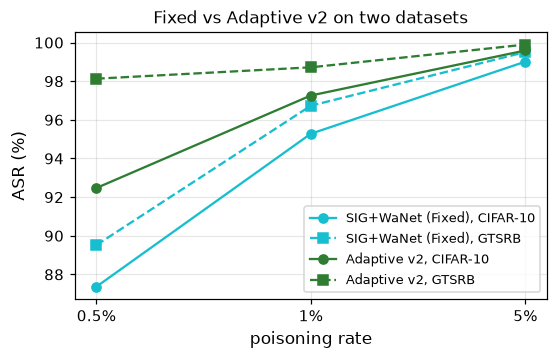

In [21]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
for name in ["SIG+WaNet (Fixed)", "Adaptive v2"]:
    d = gtsrb[gtsrb.attack == name]
    ax.plot(range(3), d.cifar_asr, "o-", color=COLORS[name], label=f"{name}, CIFAR-10")
    ax.plot(range(3), d.gtsrb_asr, "s--", color=COLORS[name], label=f"{name}, GTSRB")
ax.set_xticks(range(3)); ax.set_xticklabels(RATE_LABELS); ax.set_xlabel("poisoning rate")
ax.set_ylabel("ASR (%)"); ax.grid(alpha=0.3); ax.legend(fontsize=8.5)
ax.set_title("Fixed vs Adaptive v2 on two datasets")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/dataset_comparison.png", bbox_inches="tight"); plt.show()